# Phase 3 – KPI Calculations

## IndiaKart E-Commerce

## Objective
The objective of this phase is to calculate the key business metrics (KPIs) for IndiaKart, compare them with their targets where available, and explain what each one means for the business.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
dark_color = "#0B3C5D"
light_color = "#4FA3D1"

orders = pd.read_csv("orders_cleaned.csv", parse_dates=["order_date", "delivered_date"])
order_items = pd.read_csv("order_items_cleaned.csv")
customers = pd.read_csv("customers_cleaned.csv", parse_dates=["registration_date", "last_login_date"])
payments = pd.read_csv("payments_cleaned.csv", parse_dates=["payment_date", "refund_date"])
returns = pd.read_csv("returns_cleaned.csv", parse_dates=["return_date", "refund_date"])
inventory = pd.read_csv("inventory_cleaned.csv")

print(orders.shape, order_items.shape, customers.shape, payments.shape, returns.shape, inventory.shape)

(50000, 20) (100000, 11) (10000, 17) (50000, 13) (10000, 10) (1000, 11)


## KPI 1 – Gross Merchandise Value (GMV)

**GMV** = sum of final_amount for all orders, whatever their status. It shows the total size of the business, including orders that were cancelled.

GMV: Rs 3,147,385,545
GMV in Rs crore: 314.74
Total orders: 50000
Average GMV per month (Rs crore): 13.11
            orders  gmv_crore  share_%
status                                
Delivered    32499     205.39    65.26
Cancelled     5996      36.83    11.70
Shipped       5071      31.85    10.12
Returned      3933      24.87     7.90
Processing    2501      15.81     5.02


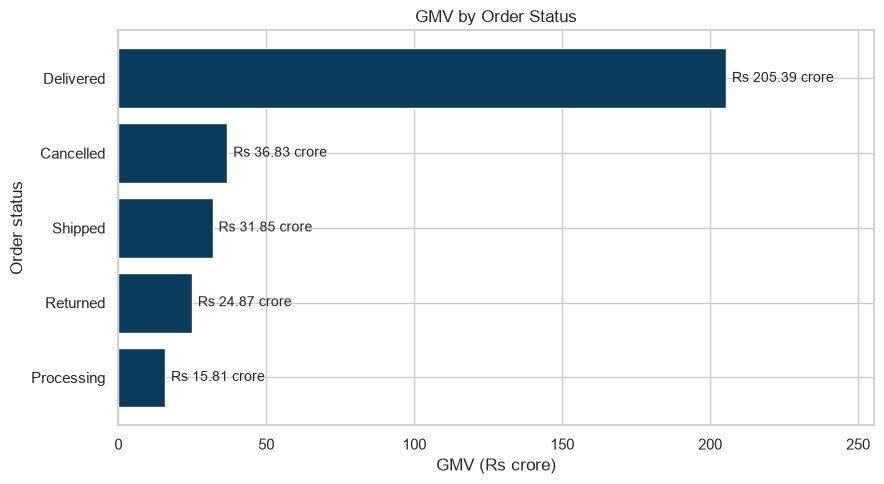

In [2]:
gmv = orders["final_amount"].sum()
print("GMV: Rs", format(round(gmv), ","))
print("GMV in Rs crore:", round(gmv / 10000000, 2))
print("Total orders:", len(orders))
print("Average GMV per month (Rs crore):", round(gmv / 10000000 / 24, 2))

# GMV for each order status
by_status = orders.groupby("status")["final_amount"].sum().sort_values(ascending=False)
print(pd.DataFrame({"orders": orders["status"].value_counts()[by_status.index],
                    "gmv_crore": (by_status / 10000000).round(2),
                    "share_%": (by_status / gmv * 100).round(2)}))

# sort so the biggest bar is at the top
by_sorted = by_status.sort_values()

plt.figure(figsize=(9, 5))
plt.barh(by_sorted.index, by_sorted.values / 10000000, color=dark_color)
for i in range(len(by_sorted)):
    plt.text(by_sorted.values[i] / 10000000 + 2, i, "Rs " + str(round(by_sorted.values[i] / 10000000, 2)) + " crore", va="center", fontsize=10)
plt.xlim(0, by_sorted.max() / 10000000 + 50)
plt.title("GMV by Order Status")
plt.xlabel("GMV (Rs crore)")
plt.ylabel("Order status")
plt.tight_layout()
plt.savefig("kpi1_gmv.png", dpi=150)
plt.show()

### Observation

IndiaKart's total order value (GMV) over the two years is Rs 314.74 crore from 50,000 orders, which is about Rs 13.1 crore a month. GMV counts every order, so it includes Rs 36.83 crore from cancelled orders and Rs 24.87 crore from returned orders, and it should be read as the size of customer demand and not as money earned. Delivered orders make up 65.26% of GMV, and the rest is either lost or still in progress, which Net Revenue (the next KPI) makes clear.

## KPI 2 – Net Revenue

**Net Revenue** = sum of final_amount for orders with the status Delivered. It is the money the platform actually earns.

Net revenue: Rs 2,053,858,612
Net revenue in Rs crore: 205.39
Delivered orders: 32499
Net revenue as % of GMV: 65.26
GMV not turned into revenue (Rs crore): 109.35


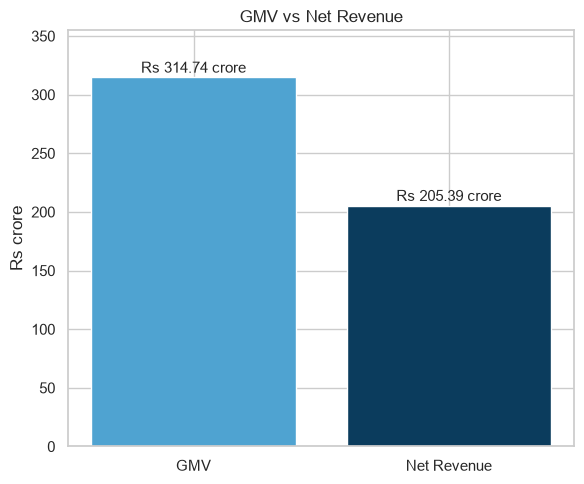

In [3]:
net_revenue = orders[orders["status"] == "Delivered"]["final_amount"].sum()
delivered_orders = (orders["status"] == "Delivered").sum()

print("Net revenue: Rs", format(round(net_revenue), ","))
print("Net revenue in Rs crore:", round(net_revenue / 10000000, 2))
print("Delivered orders:", delivered_orders)
print("Net revenue as % of GMV:", round(net_revenue / gmv * 100, 2))
print("GMV not turned into revenue (Rs crore):", round((gmv - net_revenue) / 10000000, 2))

values = [gmv / 10000000, net_revenue / 10000000]

plt.figure(figsize=(6, 5))
plt.bar(["GMV", "Net Revenue"], values, color=[light_color, dark_color])
for i in range(2):
    plt.text(i, values[i] + 4, "Rs " + str(round(values[i], 2)) + " crore", ha="center", fontsize=11)
plt.ylim(0, values[0] + 40)
plt.title("GMV vs Net Revenue")
plt.ylabel("Rs crore")
plt.tight_layout()
plt.savefig("kpi2_net_revenue.png", dpi=150)
plt.show()

### Observation

IndiaKart's net revenue is Rs 205.39 crore, which is 65.26% of the Rs 314.74 crore GMV, so for every Rs 100 of orders placed only about Rs 65 became earned revenue. The remaining Rs 109.35 crore is made up of cancelled orders (Rs 36.83 crore), returned orders (Rs 24.87 crore) and orders still shipped or being processed at the end of the period (Rs 47.66 crore). Cancellations alone are worth more than a tenth of the order value, so reducing them is the fastest way to raise net revenue without finding any new customers.

## KPI 3 – Average Order Value (AOV)

**AOV** = Net Revenue / Number of Delivered Orders. It shows how much a customer spends on an average completed order.

AOV: Rs 63197.59
Median delivered order: Rs 24167
Monthly AOV: average Rs 63088 | highest 2023-12 67894 | lowest 2024-06 57893


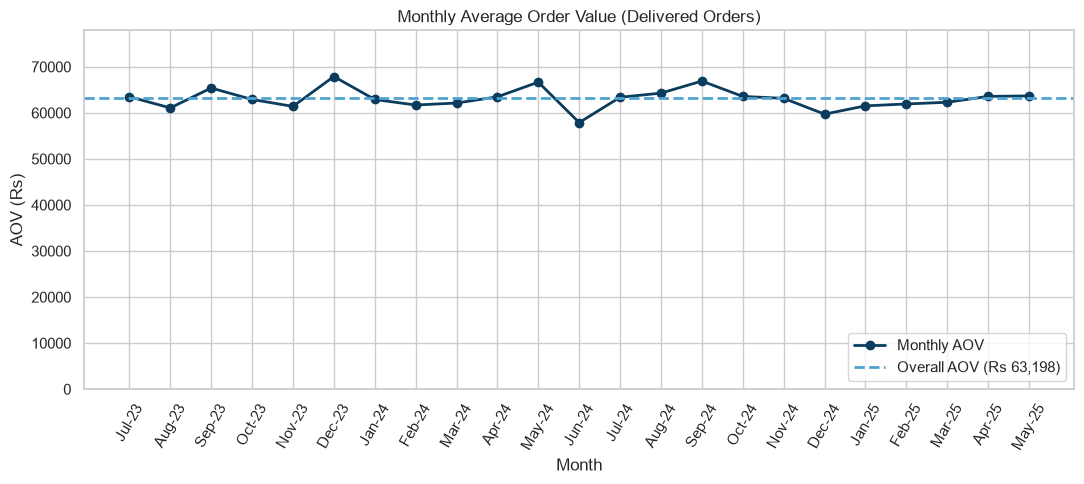

In [4]:
delivered = orders[orders["status"] == "Delivered"].copy()
aov = net_revenue / len(delivered)
print("AOV: Rs", round(aov, 2))
print("Median delivered order: Rs", round(delivered["final_amount"].median()))

# AOV for each full month (the first and last months are partial, so they are left out)
delivered["month"] = delivered["order_date"].dt.to_period("M")
monthly_aov = delivered.groupby("month")["final_amount"].mean().iloc[1:-1]
print("Monthly AOV: average Rs", round(monthly_aov.mean()), "| highest", monthly_aov.idxmax(), round(monthly_aov.max()),
      "| lowest", monthly_aov.idxmin(), round(monthly_aov.min()))

labels = monthly_aov.index.strftime("%b-%y")

plt.figure(figsize=(11, 5))
plt.plot(range(len(monthly_aov)), monthly_aov.values, color=dark_color, marker="o", linewidth=2, label="Monthly AOV")
plt.axhline(aov, color=light_color, linestyle="--", linewidth=2, label="Overall AOV (Rs " + format(round(aov), ",") + ")")
plt.xticks(range(len(monthly_aov)), labels, rotation=60)
plt.ylim(0, monthly_aov.max() + 10000)
plt.title("Monthly Average Order Value (Delivered Orders)")
plt.xlabel("Month")
plt.ylabel("AOV (Rs)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("kpi3_aov.png", dpi=150)
plt.show()

### Observation

The average order value for delivered orders is Rs 63,198, but the median order is only Rs 24,167, which means a small number of very large orders pull the average up and a typical order is much smaller. AOV moves around the overall figure from month to month, between Rs 57,893 (June 2024) and Rs 67,894 (December 2023), with no clear upward or downward trend. Since the number of orders is also flat, revenue per order is not growing either. Bundles, add-on offers and minimum-order incentives are ways to lift AOV, and the Phase 2 chart showed that AOV is almost the same for every customer segment, so these offers can be aimed at all segments.

## KPI 4 – Cancellation Rate

**Cancellation Rate** = Cancelled Orders / Total Orders × 100

Target: below 10%.

Cancelled: 5996 of 50000 | rate: 11.99 %
Months above the 10% target: 23 of 23
Highest: 2025-01 13.58 | lowest: 2024-06 11.1
Cancelled orders with a failed payment: 1748 ( 29.15 % of cancellations )
Cancellation rate without failed payments: 8.5 %
Value of cancelled orders (Rs crore): 36.83


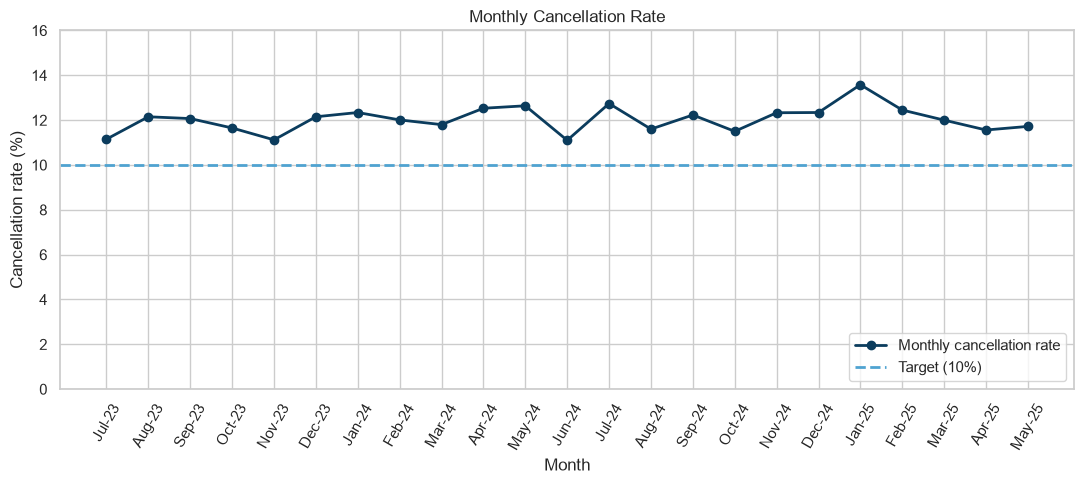

In [5]:
cancelled = (orders["status"] == "Cancelled").sum()
cancel_rate = cancelled / len(orders) * 100
print("Cancelled:", cancelled, "of", len(orders), "| rate:", round(cancel_rate, 2), "%")

# cancellation rate for each full month
orders["month"] = orders["order_date"].dt.to_period("M")
monthly_cancel = (orders.groupby("month")["status"].apply(lambda s: (s == "Cancelled").mean() * 100)).iloc[1:-1].round(2)
print("Months above the 10% target:", (monthly_cancel > 10).sum(), "of", len(monthly_cancel))
print("Highest:", monthly_cancel.idxmax(), monthly_cancel.max(), "| lowest:", monthly_cancel.idxmin(), monthly_cancel.min())

# link with failed payments
failed_orders = payments[payments["status"] == "Failed"]["order_id"].nunique()
print("Cancelled orders with a failed payment:", failed_orders, "(", round(failed_orders / cancelled * 100, 2), "% of cancellations )")
print("Cancellation rate without failed payments:", round((cancelled - failed_orders) / len(orders) * 100, 2), "%")
print("Value of cancelled orders (Rs crore):", round(orders[orders["status"] == "Cancelled"]["final_amount"].sum() / 10000000, 2))

labels2 = monthly_cancel.index.strftime("%b-%y")

plt.figure(figsize=(11, 5))
plt.plot(range(len(monthly_cancel)), monthly_cancel.values, color=dark_color, marker="o", linewidth=2, label="Monthly cancellation rate")
plt.axhline(10, color=light_color, linestyle="--", linewidth=2, label="Target (10%)")
plt.xticks(range(len(monthly_cancel)), labels2, rotation=60)
plt.ylim(0, 16)
plt.title("Monthly Cancellation Rate")
plt.xlabel("Month")
plt.ylabel("Cancellation rate (%)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("kpi4_cancellation.png", dpi=150)
plt.show()

### Observation

IndiaKart's cancellation rate is 11.99% (5,996 of 50,000 orders), which is above the 10% target, and it was above the target in every one of the 23 full months, ranging from 11.10% to 13.58%. This is a steady, structural problem and not a short-term spike. The cancelled orders were worth Rs 36.83 crore. A large part of it is linked to payments: 1,748 cancelled orders (29.15% of all cancellations) had a failed payment, and without them the cancellation rate would be 8.50%, inside the target. Improving payment success, for example with retry options and more reliable gateways for Net Banking and Wallet, is therefore the most direct way to bring cancellations below 10%.

## KPI 5 – Return Rate

**Return Rate** = Return Records / Delivered Orders × 100

Target: below 8%.

Return requests: 10000 | Delivered orders: 32499
Return rate: 30.77 %
status
Delivered    4327
Returned     3933
Cancelled    1067
Shipped       673
Name: count, dtype: int64
Delivered orders with a return request: 4327 | rate: 13.31 %
Total value of return requests (Rs crore): 64.12
refund_status
Pending     13.39
Refunded    46.89
Rejected     3.84
Name: return_amount, dtype: float64
Refunded as % of net revenue: 22.83 %


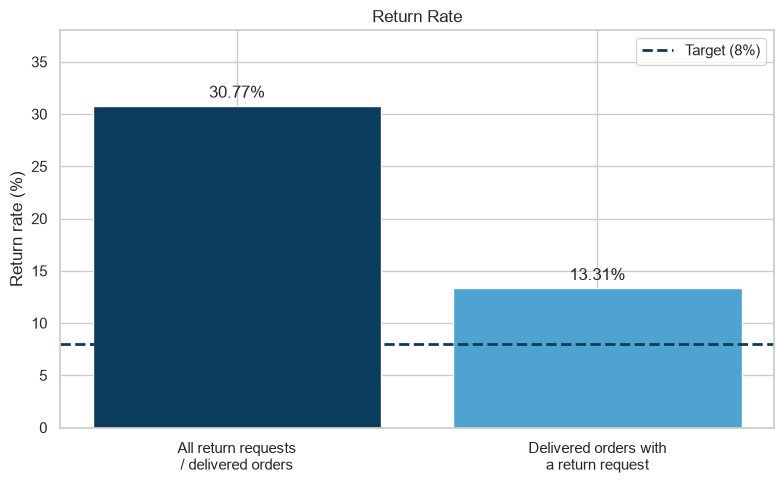

In [6]:
delivered_orders = (orders["status"] == "Delivered").sum()
return_rate = len(returns) / delivered_orders * 100
print("Return requests:", len(returns), "| Delivered orders:", delivered_orders)
print("Return rate:", round(return_rate, 2), "%")

# which orders do the return requests belong to?
return_status = orders[orders["order_id"].isin(returns["order_id"])]["status"].value_counts()
print(return_status)

# a stricter measure: delivered orders that have a return request
delivered_with_return = return_status["Delivered"]
strict_rate = delivered_with_return / delivered_orders * 100
print("Delivered orders with a return request:", delivered_with_return, "| rate:", round(strict_rate, 2), "%")

# value of the returns
print("Total value of return requests (Rs crore):", round(returns["return_amount"].sum() / 10000000, 2))
print((returns.groupby("refund_status")["return_amount"].sum() / 10000000).round(2))
refunded = returns[returns["refund_status"] == "Refunded"]["return_amount"].sum()
print("Refunded as % of net revenue:", round(refunded / net_revenue * 100, 2), "%")

rates = [return_rate, strict_rate]

plt.figure(figsize=(8, 5))
plt.bar(["All return requests\n/ delivered orders", "Delivered orders with\na return request"], rates, color=[dark_color, light_color])
for i in range(2):
    plt.text(i, rates[i] + 0.8, str(round(rates[i], 2)) + "%", ha="center", fontsize=12)
plt.axhline(8, color=dark_color, linestyle="--", linewidth=2, label="Target (8%)")
plt.ylim(0, 38)
plt.title("Return Rate")
plt.ylabel("Return rate (%)")
plt.legend()
plt.tight_layout()
plt.savefig("kpi5_return_rate.png", dpi=150)
plt.show()

### Observation

Using the formula in the project document (all return records divided by delivered orders), the return rate is 30.77%, nearly four times the 8% target. This figure is inflated because 1,740 return records belong to orders that were cancelled or only shipped, and 3,933 belong to orders already marked as Returned. Counting only delivered orders that have a return request gives a stricter rate of 13.31%, which is still well above the target. Return requests are worth Rs 64.12 crore, and the Rs 46.89 crore that has already been refunded equals 22.83% of net revenue, so returns take back almost a quarter of what IndiaKart earns. Reducing returns, especially those caused by damage, wrong products and quality (56.12% of returns, as seen in Phase 2), is one of the biggest chances to protect revenue.

## KPI 6 – Customer Lifetime Value (CLV)

**CLV** = average total_spent per customer, calculated for each customer segment.

Expectation from the project document: Premium customers should be about 3 times Regular customers.

Note: in Phase 1 we found that total_spent includes cancelled and returned orders, so a second version based only on delivered orders is shown for comparison.

segment
Premium     5.33
Regular     3.62
New         2.75
Budget      1.86
Inactive    0.32
Name: total_spent, dtype: float64
Overall average: Rs 314739
Premium / Regular: 1.47 | Premium / Budget: 2.86
segment
Premium     8.61
Regular     5.73
New         4.34
Budget      2.90
Inactive    0.56
Name: total_orders, dtype: float64
segment
Premium     3.44
Regular     2.37
New         1.78
Budget      1.22
Inactive    0.24
Name: delivered_spent, dtype: float64
Premium / Regular (delivered only): 1.45


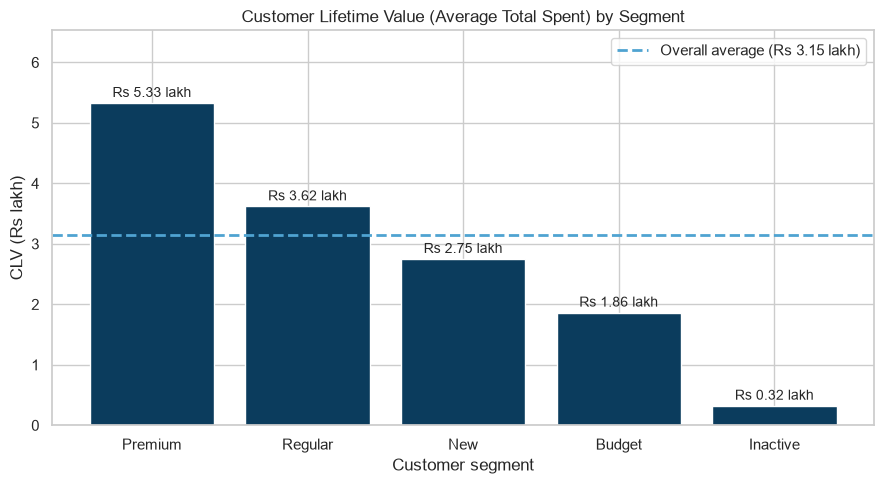

In [7]:
clv = customers.groupby("segment")["total_spent"].mean().sort_values(ascending=False)
overall_clv = customers["total_spent"].mean()
print((clv / 100000).round(2))
print("Overall average: Rs", round(overall_clv))
print("Premium / Regular:", round(clv["Premium"] / clv["Regular"], 2), "| Premium / Budget:", round(clv["Premium"] / clv["Budget"], 2))
print(customers.groupby("segment")["total_orders"].mean().round(2).sort_values(ascending=False))

# version based only on delivered orders
delivered_spend = orders[orders["status"] == "Delivered"].groupby("customer_id")["final_amount"].sum()
customers["delivered_spent"] = customers["customer_id"].map(delivered_spend).fillna(0)
clv_delivered = customers.groupby("segment")["delivered_spent"].mean().sort_values(ascending=False)
print((clv_delivered / 100000).round(2))
print("Premium / Regular (delivered only):", round(clv_delivered["Premium"] / clv_delivered["Regular"], 2))

plt.figure(figsize=(9, 5))
plt.bar(clv.index, clv.values / 100000, color=dark_color)
for i in range(len(clv)):
    plt.text(i, clv.values[i] / 100000 + 0.1, "Rs " + str(round(clv.values[i] / 100000, 2)) + " lakh", ha="center", fontsize=10)
plt.axhline(overall_clv / 100000, color=light_color, linestyle="--", linewidth=2, label="Overall average (Rs " + str(round(overall_clv / 100000, 2)) + " lakh)")
plt.ylim(0, clv.max() / 100000 + 1.2)
plt.title("Customer Lifetime Value (Average Total Spent) by Segment")
plt.xlabel("Customer segment")
plt.ylabel("CLV (Rs lakh)")
plt.legend()
plt.tight_layout()
plt.savefig("kpi6_clv.png", dpi=150)
plt.show()

### Observation

Premium customers have the highest lifetime value (about Rs 5.33 lakh each), followed by Regular (Rs 3.62 lakh), New (Rs 2.75 lakh), Budget (Rs 1.86 lakh) and Inactive customers (Rs 0.32 lakh). The ranking is as expected, but the project document expects a Premium customer to be worth about 3 times a Regular customer, and in this data the ratio is only 1.47 (1.45 when only delivered orders are counted), so that expectation is not met. Premium customers are worth about 2.9 times a Budget customer. Their higher value comes from ordering more often (8.61 orders on average against 5.73 for Regular customers) and not from bigger orders, as the AOV chart in Phase 2 showed. Because the total_spent column includes cancelled orders, the delivered-only values (for example Rs 3.44 lakh for Premium) are closer to what customers have really paid.

## KPI 7 – Month-over-Month (MoM) Growth

**MoM Growth** = (Current Month Revenue - Previous Month Revenue) / Previous Month Revenue × 100

Revenue here means net revenue (delivered orders). The first and last months of the data are partial (the data starts on 24 June 2023 and ends on 23 June 2025), so growth is calculated from August 2023 to May 2025.

Months compared: 22 ( 2023-08 to 2025-05 )
Average monthly growth: 0.57 %
Months with growth: 12 | months with decline: 10
Best month: 2025-03 16.67 % | worst month: 2024-06 -16.03 %
Latest full month (May 2025): 7.04 %
Net revenue Jul 2023: Rs 8.52 crore | May 2025: Rs 8.83 crore


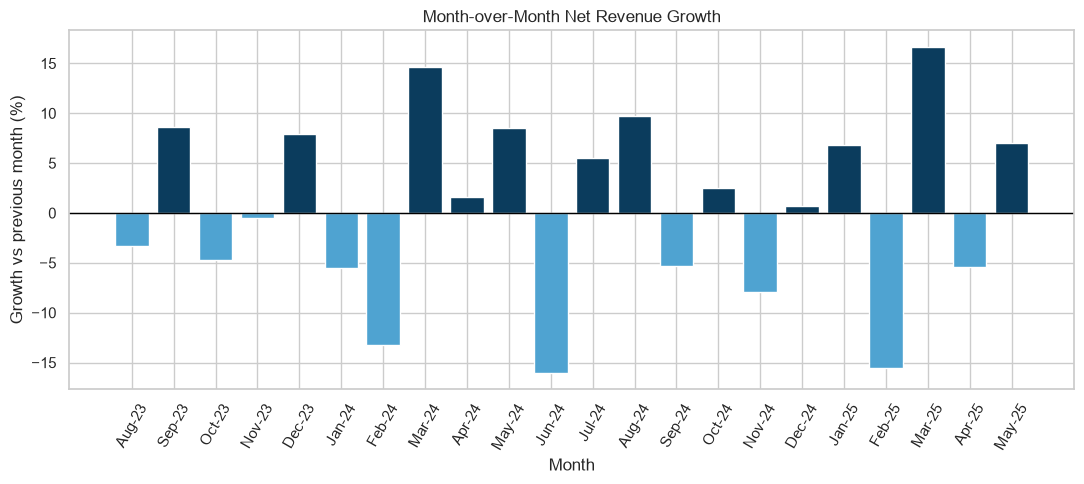

In [8]:
orders["month"] = orders["order_date"].dt.to_period("M")
monthly_net = orders[orders["status"] == "Delivered"].groupby("month")["final_amount"].sum()

# growth compared with the previous month, leaving out the partial months at the start and end
growth = (monthly_net.pct_change() * 100).round(2)
growth = growth.iloc[2:-1]

print("Months compared:", len(growth), "(", growth.index[0], "to", growth.index[-1], ")")
print("Average monthly growth:", round(growth.mean(), 2), "%")
print("Months with growth:", (growth > 0).sum(), "| months with decline:", (growth < 0).sum())
print("Best month:", growth.idxmax(), growth.max(), "% | worst month:", growth.idxmin(), growth.min(), "%")
print("Latest full month (May 2025):", growth.iloc[-1], "%")
print("Net revenue Jul 2023: Rs", round(monthly_net.loc["2023-07"] / 10000000, 2), "crore | May 2025: Rs", round(monthly_net.loc["2025-05"] / 10000000, 2), "crore")

# growth in the dark color, decline in the light color
growth_colors = []
for g in growth.values:
    if g >= 0:
        growth_colors.append(dark_color)
    else:
        growth_colors.append(light_color)

plt.figure(figsize=(11, 5))
plt.bar(range(len(growth)), growth.values, color=growth_colors)
plt.axhline(0, color="black", linewidth=1)
plt.xticks(range(len(growth)), growth.index.strftime("%b-%y"), rotation=60)
plt.title("Month-over-Month Net Revenue Growth")
plt.xlabel("Month")
plt.ylabel("Growth vs previous month (%)")
plt.tight_layout()
plt.savefig("kpi7_mom_growth.png", dpi=150)
plt.show()

### Observation

Net revenue grew by an average of only 0.57% a month between August 2023 and May 2025. Growth was positive in 12 months and negative in 10, and the month-to-month swings are large, from +16.67% in March 2025 to -16.03% in June 2024. The overall effect is almost no growth: monthly net revenue was Rs 8.52 crore in July 2023 and Rs 8.83 crore in May 2025, a rise of only about 3.6% over 22 months. The most recent full month (May 2025) grew 7.04%, which is encouraging, but it followed a 5.46% fall in April, so it does not yet show a trend. IndiaKart's revenue is stable but not growing, which agrees with the flat year-over-year result seen in Phase 2.

## KPI 8 – Top Category Revenue Share

**Top Category Revenue Share** = Revenue of the Top Category / Total Revenue × 100

If one category is above 60% of revenue, it is flagged as a concentration risk. Revenue here comes from the items of delivered orders.

Revenue from delivered items (Rs crore): 186.42
                  revenue_crore  share_%
category                                
Electronics              107.64    57.74
Sports & Fitness          31.92    17.13
Home & Kitchen            15.76     8.46
Fashion                    9.69     5.20
Automotive                 8.06     4.33
Office Supplies            6.07     3.26
Toys & Baby                2.99     1.60
Beauty & Health            2.17     1.16
Grocery                    1.21     0.65
Books                      0.90     0.48
Top category: Electronics 57.74 %
Top 2 share: 74.87 % | top 3 share: 83.33 %
Electronics share of items sold: 10.16 %


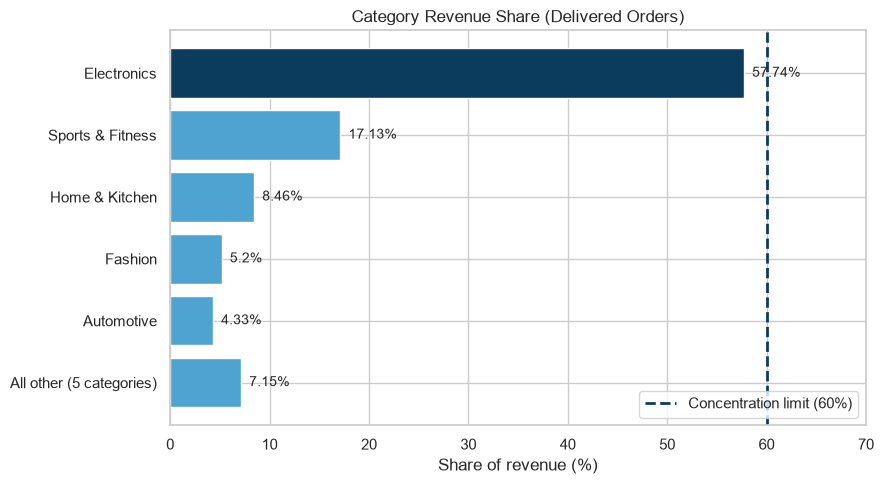

In [9]:
items = order_items.merge(orders[["order_id", "status"]], on="order_id", how="left")
delivered_items = items[items["status"] == "Delivered"]

category_revenue = delivered_items.groupby("category")["total_price"].sum().sort_values(ascending=False)
category_share = (category_revenue / category_revenue.sum() * 100).round(2)

print("Revenue from delivered items (Rs crore):", round(category_revenue.sum() / 10000000, 2))
print(pd.DataFrame({"revenue_crore": (category_revenue / 10000000).round(2), "share_%": category_share}))
print("Top category:", category_share.index[0], category_share.iloc[0], "%")
print("Top 2 share:", category_share.head(2).sum().round(2), "% | top 3 share:", category_share.head(3).sum().round(2), "%")
print("Electronics share of items sold:", round((delivered_items["category"] == "Electronics").mean() * 100, 2), "%")

# top 5 categories and the rest combined
top5 = category_share.head(5)
others = round(category_share.iloc[5:].sum(), 2)
names = list(top5.index) + ["All other (5 categories)"]
values = list(top5.values) + [others]
names.reverse()
values.reverse()

plt.figure(figsize=(9, 5))
plt.barh(names, values, color=[light_color] * (len(values) - 1) + [dark_color])
for i in range(len(values)):
    plt.text(values[i] + 0.8, i, str(values[i]) + "%", va="center", fontsize=10)
plt.axvline(60, color=dark_color, linestyle="--", linewidth=2, label="Concentration limit (60%)")
plt.xlim(0, 70)
plt.title("Category Revenue Share (Delivered Orders)")
plt.xlabel("Share of revenue (%)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("kpi8_top_category.png", dpi=150)
plt.show()

### Observation

Electronics is by far the biggest category, contributing 57.74% of the revenue from delivered items (Rs 107.64 crore). This is just below the 60% limit that marks a concentration risk, so it is not flagged, but it is very close. Electronics with Sports & Fitness (17.13%) bring in 74.87% of revenue, and the top three categories bring in 83.33%. Electronics is only 10.16% of the items sold, so it earns so much because each item is expensive (about Rs 163,000 on average), which means a small change in electronics demand, pricing or returns would have a large effect on total revenue. IndiaKart should grow its smaller categories, especially Home & Kitchen and Fashion, to reduce this dependence. These shares cover delivered orders that have line items, which is about 91% of net revenue.

## KPI 9 – Payment Failure Rate

**Payment Failure Rate** = Failed Payments / Total Payment Attempts × 100

Target: below 2%.

Failed payments: 1748 of 50000 | failure rate: 3.5 %
Value of failed payments (Rs crore): 10.74
Months above the 2% target: 23 of 23
Lowest month: 2023-09 2.8 | highest month: 2025-01 4.15
gateway
Razorpay      3.80
CCAvenue      3.72
Google Pay    3.69
PayU          3.47
Paytm         3.31
PhonePe       3.31
BillDesk      3.17
Name: status, dtype: float64


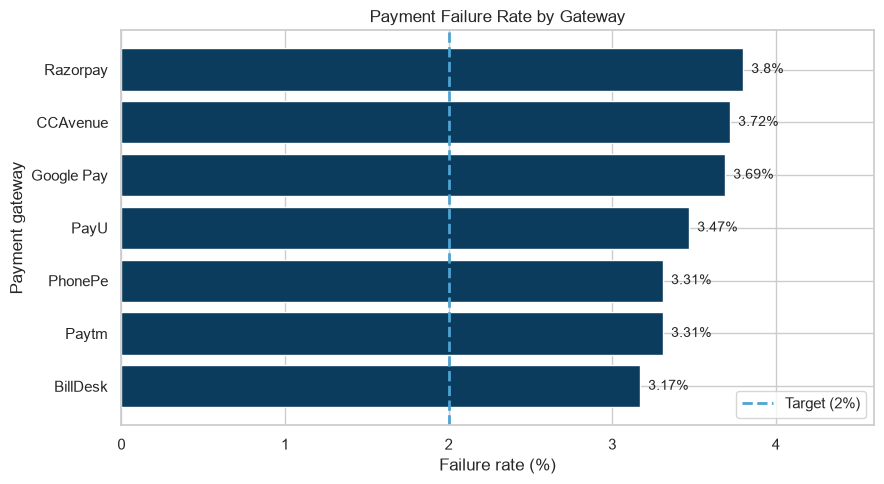

In [10]:
failed = payments["status"] == "Failed"
failure_rate = failed.mean() * 100
print("Failed payments:", failed.sum(), "of", len(payments), "| failure rate:", round(failure_rate, 2), "%")
print("Value of failed payments (Rs crore):", round(payments[failed]["amount"].sum() / 10000000, 2))

# failure rate for each full month
payments["month"] = payments["payment_date"].dt.to_period("M")
monthly_fail = payments.groupby("month")["status"].apply(lambda s: (s == "Failed").mean() * 100).iloc[1:-1].round(2)
print("Months above the 2% target:", (monthly_fail > 2).sum(), "of", len(monthly_fail))
print("Lowest month:", monthly_fail.idxmin(), monthly_fail.min(), "| highest month:", monthly_fail.idxmax(), monthly_fail.max())

# failure rate for each payment gateway
gateway_fail = payments.groupby("gateway")["status"].apply(lambda s: round((s == "Failed").mean() * 100, 2)).sort_values(ascending=False)
print(gateway_fail)

# sort so the highest bar is at the top
g_sorted = gateway_fail.sort_values()

plt.figure(figsize=(9, 5))
plt.barh(g_sorted.index, g_sorted.values, color=dark_color)
for i in range(len(g_sorted)):
    plt.text(g_sorted.values[i] + 0.05, i, str(g_sorted.values[i]) + "%", va="center", fontsize=10)
plt.axvline(2, color=light_color, linestyle="--", linewidth=2, label="Target (2%)")
plt.xlim(0, 4.6)
plt.title("Payment Failure Rate by Gateway")
plt.xlabel("Failure rate (%)")
plt.ylabel("Payment gateway")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("kpi9_payment_failure.png", dpi=150)
plt.show()

### Observation

The payment failure rate is 3.50% (1,748 of 50,000 attempts), which is above the 2% target, and failed payments were worth Rs 10.74 crore. The rate was above 2% in all 23 full months, between 2.80% (September 2023) and 4.15% (January 2025), so this is a lasting problem and not a one-off. It is also not caused by one gateway: all seven are above the target, from 3.17% (BillDesk) to 3.80% (Razorpay), and Phase 2 showed that all payment methods have similar failure rates (2.96% to 3.95%). Since every failed payment belongs to a cancelled order (Phase 1), and the cancellation KPI showed that failed payments explain 29.15% of cancellations, improving the payment success rate would directly raise both the cancellation rate and net revenue. Retry options, backup gateways and better monitoring of the weakest gateway and payment methods are the first steps.

## KPI 10 – Inventory Fill Rate

**Inventory Fill Rate** = Products In Stock / Total Products × 100

A product counts as "In Stock" when its status is In Stock. Low Stock and Out of Stock products are not counted.

Target: above 95%.

Products in stock: 922 of 1000 | fill rate: 92.2 %
status
In Stock        922
Low Stock        76
Out of Stock      2
Name: count, dtype: int64
Products that would need to move to In Stock to reach 95%: 28
Inventory value (Rs crore): 211.19 | value of low or out-of-stock products (Rs crore): 0.81
warehouse_location
Hyderabad-WH4    89.22
Bengaluru-WH3    90.06
Kolkata-WH6      92.17
Delhi-WH2        93.33
Chennai-WH5      93.68
Mumbai-WH1       95.04
Name: status, dtype: float64
Lowest categories: {'Office Supplies': 86.0, 'Books': 90.0, 'Beauty & Health': 91.0} | highest: {'Electronics': 95.0, 'Sports & Fitness': 96.0}


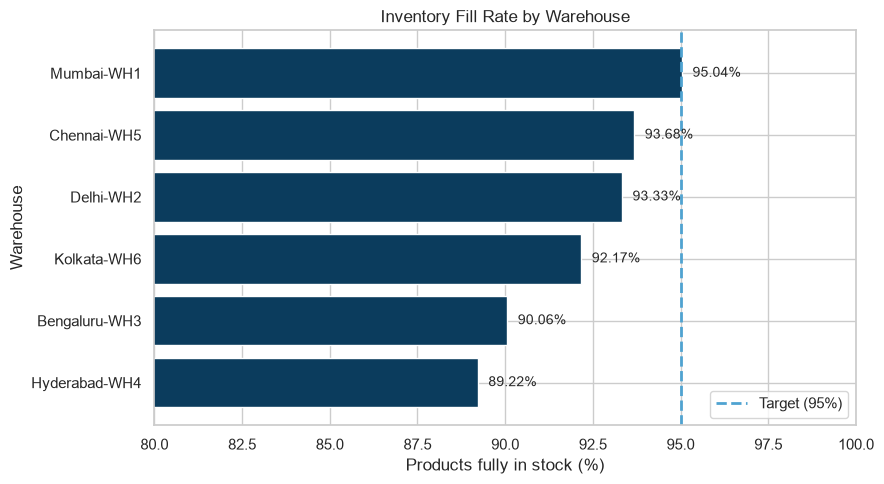

In [13]:
products = pd.read_csv("products_cleaned.csv")
in_stock = (inventory["status"] == "In Stock").sum()
fill_rate = in_stock / len(inventory) * 100
print("Products in stock:", in_stock, "of", len(inventory), "| fill rate:", round(fill_rate, 2), "%")
print(inventory["status"].value_counts())
print("Products that would need to move to In Stock to reach 95%:", int(0.95 * len(inventory)) - in_stock)
print("Inventory value (Rs crore):", round(inventory["total_inventory_value"].sum() / 10000000, 2),
      "| value of low or out-of-stock products (Rs crore):", round(inventory[inventory["status"] != "In Stock"]["total_inventory_value"].sum() / 10000000, 2))

# fill rate for each warehouse
warehouse_fill = inventory.groupby("warehouse_location")["status"].apply(lambda s: round((s == "In Stock").mean() * 100, 2)).sort_values()
print(warehouse_fill)

# fill rate for each category
inv = inventory.merge(products[["product_id", "category"]], on="product_id", how="left")
category_fill = inv.groupby("category")["status"].apply(lambda s: round((s == "In Stock").mean() * 100, 2)).sort_values()
print("Lowest categories:", category_fill.head(3).to_dict(), "| highest:", category_fill.tail(2).to_dict())

plt.figure(figsize=(9, 5))
plt.barh(warehouse_fill.index, warehouse_fill.values, color=dark_color)
for i in range(len(warehouse_fill)):
    plt.text(warehouse_fill.values[i] + 0.3, i, str(warehouse_fill.values[i]) + "%", va="center", fontsize=10)
plt.axvline(95, color=light_color, linestyle="--", linewidth=2, label="Target (95%)")
plt.xlim(80, 100)
plt.title("Inventory Fill Rate by Warehouse")
plt.xlabel("Products fully in stock (%)")
plt.ylabel("Warehouse")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("kpi10_fill_rate.png", dpi=150)
plt.show()

### Observation

Inventory fill rate is 92.2%: 922 of 1,000 products are fully in stock, 76 are on low stock and 2 are out of stock (both in the Automotive category), which is below the 95% target. 28 more products would need to be fully stocked to reach it. Only the Mumbai warehouse (95.04%) meets the target, while Hyderabad (89.22%) and Bengaluru (90.06%) are weakest. By category, Office Supplies (86.00%) and Books (90.00%) have the lowest fill rates, while the best-selling categories, Electronics (95.00%) and Sports & Fitness (96.00%), are at or close to the target. Low and out-of-stock items hold only Rs 0.81 crore of the Rs 211.19 crore inventory, so the gap is not a large financial problem, but it can still cost sales on specific products. Re-ordering earlier for low-stock items in the Hyderabad and Bengaluru warehouses would close most of the gap.

summary = pd.DataFrame({
    "No": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "KPI": ["GMV", "Net Revenue", "Average Order Value", "Cancellation Rate", "Return Rate",
            "CLV (Premium / Regular)", "Average MoM Growth (net revenue)", "Top Category Revenue Share (Electronics)",
            "Payment Failure Rate", "Inventory Fill Rate"],
    "Value": ["Rs 314.74 crore", "Rs 205.39 crore", "Rs 63,198", "11.99%", "30.77%",
              "Rs 5.33 lakh / Rs 3.62 lakh (1.47x)", "0.57%", "57.74%", "3.50%", "92.2%"],
    "Target": ["-", "-", "-", "below 10%", "below 8%", "about 3x", "-", "below 60%", "below 2%", "above 95%"],
    "Status": ["-", "-", "-", "Not met", "Not met", "Not met", "-", "Met (close to limit)", "Not met", "Not met"],
})
summary

## Key Insights

**Revenue and growth**
- IndiaKart's GMV over the two years is Rs 314.74 crore, but net revenue (delivered orders) is Rs 205.39 crore, only 65.26% of GMV. The other Rs 109.35 crore was lost to cancellations (Rs 36.83 crore), returned orders (Rs 24.87 crore), or was still in progress (Rs 47.66 crore).
- Growth is almost flat. Net revenue grew by an average of only 0.57% a month, with large swings (from -16.03% to +16.67%), and monthly net revenue rose only about 3.6% in 22 months.
- The average order value is Rs 63,198, but the typical order (median) is only Rs 24,167, so a few very large orders lift the average.

**Customers**
- Premium customers have the highest lifetime value (Rs 5.33 lakh), but only 1.47 times a Regular customer (Rs 3.62 lakh), which is below the expected 3 times. Their value comes from ordering more often (8.61 orders against 5.73), not from larger orders.
- Categories: Electronics brings in 57.74% of delivered revenue, just under the 60% concentration limit, and the top two categories bring in 74.87%.

**Targets that are not met**
| KPI | Result | Target |
|---|---|---|
| Cancellation rate | 11.99% | below 10% |
| Return rate | 30.77% (13.31% on a stricter basis) | below 8% |
| Payment failure rate | 3.50% | below 2% |
| Inventory fill rate | 92.2% | above 95% |

**Connections between the KPIs**
- Payments and cancellations are linked: 29.15% of cancellations (1,748 orders) involve a failed payment, and without them the cancellation rate would be 8.50%, inside the target.
- Returns are expensive: the Rs 46.89 crore already refunded equals 22.83% of net revenue. More than half of returns come from product or delivery problems.
- Fill rate is weakest in the Hyderabad (89.22%) and Bengaluru (90.06%) warehouses and in the Office Supplies (86.00%) and Books (90.00%) categories.

**Recommendations**
1. Fix payments first. Add retry options and backup gateways, and monitor the weakest gateway (Razorpay, 3.80%) and payment methods (Net Banking and Wallet). This reduces both failures and cancellations.
2. Reduce returns by improving quality checks, packaging and product descriptions, and review return requests on cancelled and shipped orders.
3. Grow revenue beyond a flat base: raise order value with bundles and add-on offers, increase order frequency for Premium customers, and expand smaller categories to reduce the dependence on Electronics.
4. Re-order earlier for low-stock products, starting with the Hyderabad and Bengaluru warehouses and the two out-of-stock Automotive products.